# Deliberation allocation: method in practice

**Level:** 2  
**Prerequisites:** Deliberation allocation level 1  
**Reading time:** 25 minutes

**Question:** How do the released fast policies execute the C13 case when no live planner call is configured?


## Objectives

For level 2 of deliberation allocation on C13, Separate a fast policy decision from an optional planner call. For level 2 of deliberation allocation on C13, Delegation is useful only when the change in independently verified outcome pays for planner delay, invalid proposals and unused work under the same observed candidate state.


## Setup

The versions below are pinned in `notebooks/requirements.txt` and are also recorded in this notebook's metadata.

```bash
pip install reflexmesh==0.1.2 numpy==2.5.3 matplotlib==3.11.2 torch==2.14.1 joblib==1.6.0 gymnasium==1.4.0 scikit-learn==1.9.1 stable-baselines3==2.9.2 sb3-contrib==2.9.2
```


In [1]:
# Import the released policy API and the pinned plotting/runtime dependencies.
import hashlib
import importlib.metadata
import json
import os
from io import BytesIO
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
from reflexmesh.environments import CaseSpec
from reflexmesh.evaluation.runner import aggregate, run_episode
from reflexmesh.pipeline import make_policy
from reflexmesh.planners import OllamaPlanner

for distribution in ("reflexmesh", "numpy", "matplotlib"):
    print(f"{distribution}=={importlib.metadata.version(distribution)}")


reflexmesh==0.1.2
numpy==2.5.3
matplotlib==3.11.2


## Data
For level 2 of deliberation allocation on C13, The notebook reads committed product artifacts. For level 2 of deliberation allocation on C13, Owner: For level 2 of deliberation allocation on C13, Neuraxis. For level 2 of deliberation allocation on C13, Repository: For level 2 of deliberation allocation on C13, https://github.com/fsantibanezleal/CAOS_Neuraxis. License: For level 2 of deliberation allocation on C13, Apache-2.0. For level 2 of deliberation allocation on C13, The JSON is a first-party, frozen experiment artifact; For level 2 of deliberation allocation on C13, no external benchmark data are redistributed in this notebook.

For level 2 of deliberation allocation on C13, This notebook reads `data/derived/index.json` and the listed trace artifacts. For level 2 of deliberation allocation on C13, The method run uses an isolated Reflexmesh case workspace. For level 2 of deliberation allocation on C13, For learned methods, fetch the exact public release assets with `python -m reflexmesh.cli fetch-models --destination models/checkpoints --version v0.01.000`, then set `NEURAXIS_CHECKPOINTS` to that folder. For level 2 of deliberation allocation on C13, The release manifest verifies asset hashes. For level 2 of deliberation allocation on C13, Planner methods M09/M10 are read from frozen traces unless `NEURAXIS_NOTEBOOK_MODEL` explicitly names a configured local Ollama model.

For level 2 of deliberation allocation on C13, Artifacts for this lesson:

- `data/derived/index.json`
- `data/derived/semantic-routing-study/analysis.json`
- `data/derived/episodes/M11-C13-nominal-40000.json`
- `data/derived/episodes/M12-C13-nominal-40000.json`
- `data/derived/episodes/M09-C13-nominal-40000.json`
- `data/derived/episodes/M10-C13-nominal-40000.json`


## Method

For level 2 of deliberation allocation on C13, A planner response is a proposal with measured cost, not an automatic improvement. For level 2 of deliberation allocation on C13, The fast controller observes a bounded candidate set; For level 2 of deliberation allocation on C13, the planner sees only the request allowed by its interface and may return a late, invalid or unused answer. For level 2 of deliberation allocation on C13, The relevant comparison is paired on the same features and causal history, then charged for elapsed planner time. For level 2 of deliberation allocation on C13, Neuraxis's fitted gate had only seven positive labels among 228 states and selected threshold 1.01, which means it never crossed the delegation threshold. For level 2 of deliberation allocation on C13, This is a negative result about this training and selection procedure, not proof that all fast/slow systems fail. For level 2 of deliberation allocation on C13, A configured local Ollama model is optional and must never be confused with the frozen planner traces. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, A delegation gate should compare the expected value of a slower planner response with the fast policy's verified outcome, including planner latency, invalid proposals and the cost of unused reasoning. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, The frozen C13 traces reveal when the experimental controller requested deliberation, but a replay cannot establish that a live model would return a useful action under changed context. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, A fair allocation experiment pairs fast-only and delegated runs on the same observation, tools and task contract, then records decision quality and wall-clock cost as separate outcomes. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, Positive gate examples must include cases where deliberation changes a consequential choice. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, otherwise a learned gate can minimize loss by never delegating and appear successful without learning allocation. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, A large language model is a stochastic external component, so its model identity, prompt, decoding settings, timeout behavior and invalid-output handling belong in the experiment record. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, For this level, record whether the gate actually invokes the planner, whether its proposal is admissible, and whether the final verified outcome changes after paying its delay. For level 2 of deliberation allocation on C13, At level 2, for deliberation allocation on C13, A useful extension introduces ambiguous observations with positive delegation value and negative controls where the fast policy is already sufficient.


### deliberation allocation · level 2 — Verify the audit and each trace's bytes before interpreting outcomes.


In [2]:
# Load and hash-check the selected first-party traces; never edit the canonical artifacts.
ROOT = Path("../../../").resolve()
index_path = ROOT / "data/derived/index.json"
index_bytes = index_path.read_bytes()
index = json.loads(index_bytes)
audit = json.loads((ROOT / "data/derived/benchmark-adequacy.json").read_text(encoding="utf-8"))
assert hashlib.sha256(index_bytes).hexdigest() == audit["index_sha256"]
selected_methods = ["M11", "M12", "M09", "M10"]
trace_methods = ["M11", "M12", "M09", "M10"]
sample_case = "C13"
seed = 40000
records = {}
for method_id in trace_methods:
    row = next(
        record
        for record in index["episodes"]
        if record["method_id"] == method_id
        and record["case_id"] == sample_case
        and record["variant"] == "nominal"
        and record["seed"] == seed
    )
    trace_path = ROOT / "data/derived" / row["path"]
    trace_bytes = trace_path.read_bytes()
    assert hashlib.sha256(trace_bytes).hexdigest() == row["sha256"]
    records[method_id] = json.loads(trace_bytes)
checkpoint_dir = Path(os.environ.get("NEURAXIS_CHECKPOINTS", str(ROOT / "models/checkpoints")))
planner_model = os.environ.get("NEURAXIS_NOTEBOOK_MODEL")
planner = OllamaPlanner(planner_model) if planner_model else None
print("Hash-verified trace records:", len(records))


Hash-verified trace records: 4


### deliberation allocation · level 2 — Execute the released policies and compare the run


### deliberation allocation · level 2 — Compare the full sequence, not only the first action


### deliberation allocation · L2 — Build the first executable policy

In level 2, construct policy M11 for deliberation allocation with the public factory and keep its observation contract unchanged before sampling C13.


In [3]:
# Construct the first released policy through the public factory.
primary_id = "M11"
primary_policy = make_policy(primary_id, checkpoint_dir, planner=planner)
print("Primary policy:", primary_id)


Primary policy: M11


### deliberation allocation · L2 — Execute the primary method on the named case

At level 2, the deliberation allocation evaluator runs M11 on C13 and derives success from the independent task postcondition, not from a replayed trace.


In [4]:
# Run the policy and verify the case postcondition independently.
primary_result = run_episode(primary_policy, CaseSpec(sample_case, "nominal", seed))
print("Primary task success:", primary_result["metrics"]["task_success"])


Primary task success: 1


### deliberation allocation · L2 — Construct an independent comparison policy

For level 2 of deliberation allocation, create M12 as a fresh object so recurrent state from M11 cannot leak into the matched comparison.


In [5]:
# Create a fresh policy object for the matched comparison.
secondary_id = "M12"
secondary_policy = make_policy(secondary_id, checkpoint_dir, planner=planner)
print("Comparison policy:", secondary_id)


Comparison policy: M12


### deliberation allocation · L2 — Run the comparison under identical conditions

This level 2 comparison runs M12 on the same C13, nominal variant and seed, and it illustrates behavior rather than estimating a population rate.


In [6]:
# Use the same case, variant and seed for the second policy.
secondary_result = run_episode(secondary_policy, CaseSpec(sample_case, "nominal", seed))
print("Comparison task success:", secondary_result["metrics"]["task_success"])


Comparison task success: 1


### deliberation allocation · L2 — Aggregate the two executed episodes

At level 2, the package aggregator summarizes two executed deliberation allocation episodes, and cross-family claims still require the complete benchmark below.


In [7]:
# Aggregate executed outcomes with the package's descriptive evaluator.
fresh_runs = {primary_id: primary_result, secondary_id: secondary_result}
fresh_summary = aggregate([primary_result, secondary_result])
print("Fresh policy runs:", len(fresh_runs))
print("Fresh successes:", sum(run["metrics"]["task_success"] for run in fresh_runs.values()))


Fresh policy runs: 2
Fresh successes: 2


### deliberation allocation · L2 — Fresh policy outcomes

For level 2 of deliberation allocation on C13, The next plot is computed from the deliberation allocation episode results just executed for C13 rather than copied from a frozen artifact.


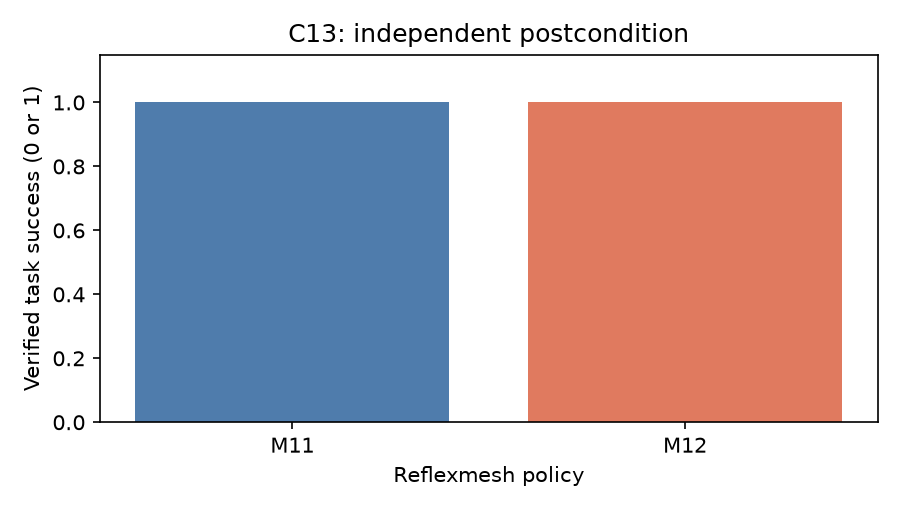

In [8]:
# Plot the independently verified outcomes from the two fresh policy runs.
labels = list(fresh_runs)
success = [fresh_runs[name]["metrics"]["task_success"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, success, color=["#4f7cac", "#e07a5f"])
ax.set_ylim(0, 1.15)
ax.set_ylabel("Verified task success (0 or 1)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: independent postcondition")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


For level 2 of deliberation allocation on C13, For deliberation allocation, these bars show fresh task-postcondition outcomes for M11 and M12 on C13, with success encoded as 1 and failure as 0. For level 2 of deliberation allocation on C13, Read the case and seed before comparing them. For level 2 of deliberation allocation on C13, This controlled episode illustrates policy behavior but is not a confidence interval and does not establish generalization to other software tasks.


### deliberation allocation · L2 — Recorded controller time

At level 2, the deliberation allocation timing chart uses hash-verified frozen records for M11 and M12 on C13, not machine-dependent timings from fresh episodes. This level 2 deliberation allocation view describes the recorded environment under its declared case, variant and seed.

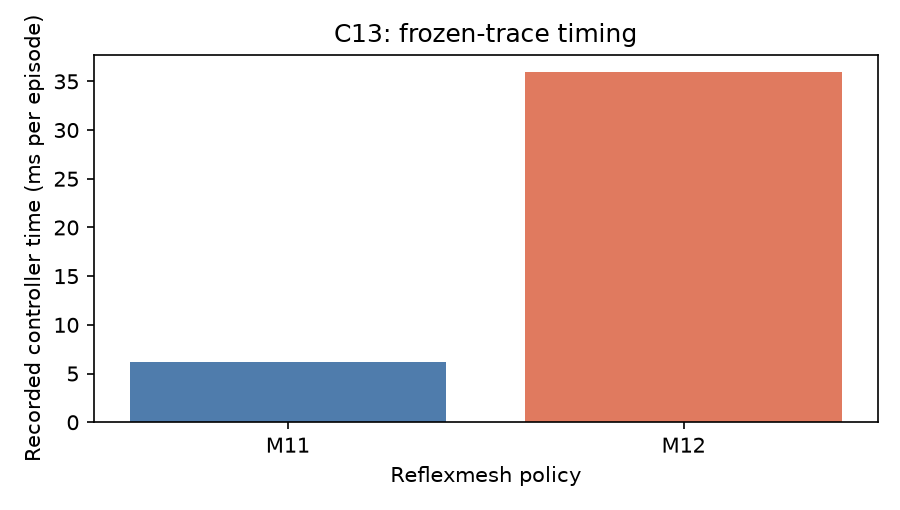

In [9]:
# Plot controller time from the hash-verified frozen records for the matched methods.
labels = list(fresh_runs)
latencies = [records[name]["metrics"]["controller_ms"] for name in labels]
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(labels, latencies, color=["#4f7cac", "#e07a5f"])
ax.set_ylabel("Recorded controller time (ms per episode)")
ax.set_xlabel("Reflexmesh policy")
ax.set_title(f"{sample_case}: frozen-trace timing")
fig.tight_layout()
image_buffer = BytesIO()
fig.savefig(image_buffer, format="png", dpi=150)
display(Image(data=image_buffer.getvalue()))
image_buffer.close()
plt.close(fig)


The level 2 deliberation allocation chart reads canonical M11/M12 records for C13, nominal variant and seed 40000 after the data boundary verifies their hashes. For this deliberation allocation lesson, the stable figure describes recorded latency and intentionally makes no current-machine speed claim.

## Results

**Answer:** The deliberation allocation comparison executes 2 fresh policy episodes, M11 and M12, under identical C13 conditions; keep the deliberation allocation family and seed strata in view because the frozen matrix contains designed, not population-sampled, tasks.

For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, The gate fit used 228 states with seven positive labels and selected threshold 1.01, meaning it never delegated through that gate. For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, M12's other trigger is separate. For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, Report planner calls, latency and verified success; For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, For level 2 of deliberation allocation on C13, a configured LLM is not evidence of useful deliberation.


## Summary

For level 2 of deliberation allocation on C13, At level 2, deliberation allocation uses C13 to show how the released method behaves under one declared condition. For level 2 of deliberation allocation on C13, Keep the observed outcome separate from a claim about general software-control intelligence.


## References

- [JEV](https://typesafe.ai/blog/introducing-system-one-models-and-jev)
- [DPT](https://aclanthology.org/2025.acl-long.206/)
- [VOC](https://arxiv.org/abs/1711.06892)
- [DEFER](https://proceedings.mlr.press/v119/mozannar20b.html)
